Episode    0 | Reward:  -167.76 | 10-episode avg:  -167.76
Episode   10 | Reward:    -6.06 | 10-episode avg:   -94.56
Episode   20 | Reward:   -10.89 | 10-episode avg:   -10.94
Episode   30 | Reward:    -6.83 | 10-episode avg:    -7.75
Episode   40 | Reward:    -5.22 | 10-episode avg:    -8.67
Episode   50 | Reward:    -7.00 | 10-episode avg:    -9.53
Episode   60 | Reward:    -4.04 | 10-episode avg:    -9.62
Episode   70 | Reward:   -20.01 | 10-episode avg:    -6.56
Episode   80 | Reward:    -2.47 | 10-episode avg:    -7.52
Episode   90 | Reward:    -3.10 | 10-episode avg:    -7.55
Episode  100 | Reward:    -8.57 | 10-episode avg:    -7.10
Episode  110 | Reward:    -9.61 | 10-episode avg:    -8.94
Episode  120 | Reward:    -6.08 | 10-episode avg:    -4.92
Episode  130 | Reward:   -10.23 | 10-episode avg:    -6.96
Episode  140 | Reward:    -2.41 | 10-episode avg:    -8.98
Episode  150 | Reward:    -2.55 | 10-episode avg:   -10.01
Episode  160 | Reward:    -3.78 | 10-episode avg:    -8.

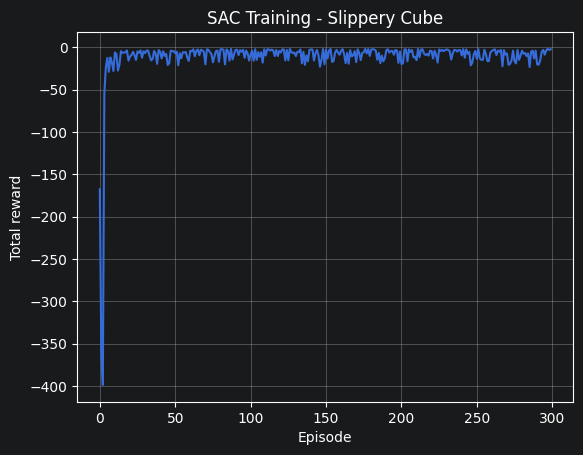

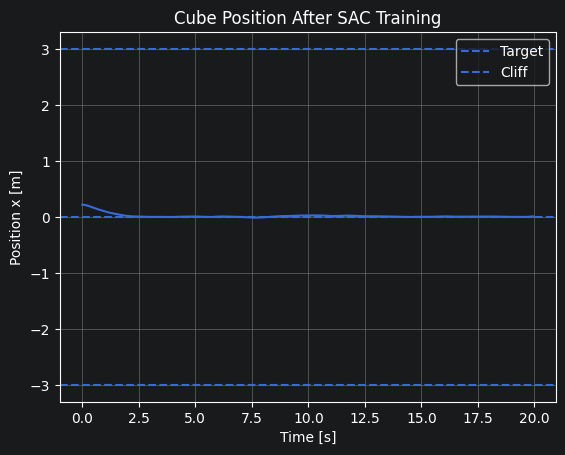

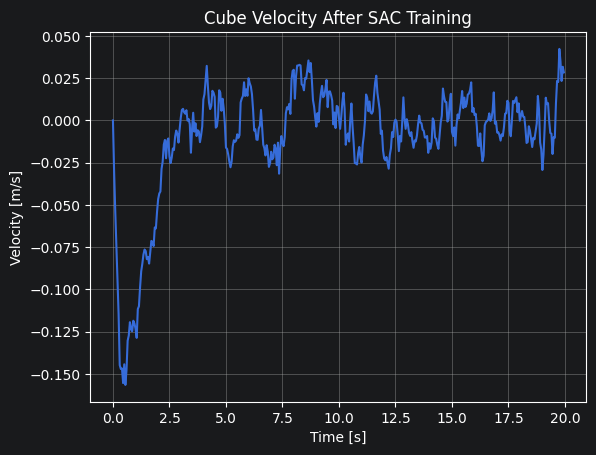

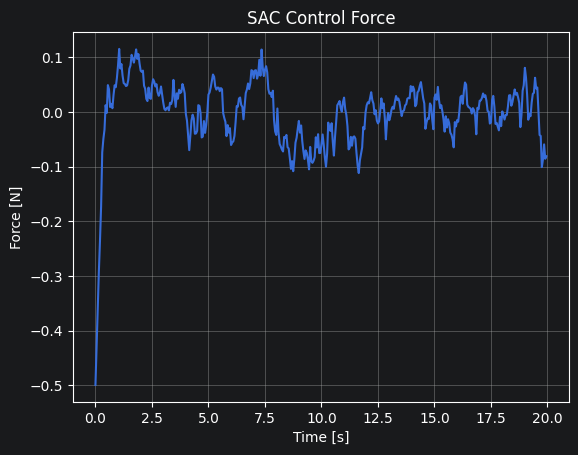

In [1]:
# ============================================================
# Soft Actor-Critic (SAC) - Slippery Cube Example
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random
import matplotlib.pyplot as plt


# ============================================================
# 1. ENVIRONMENT
# ============================================================

class SlipperyCubeEnv:
    """
    A cube slides along a 1D surface.

    State:
        s = [x, v]
        x = position
        v = velocity

    Action:
        force in [-max_force, max_force]

    Goal:
        Stabilize the cube around x = 0 despite random disturbances.
    """

    def __init__(self):
        self.dt = 0.05
        self.mass = 1.0
        self.friction = 0.05

        self.x_limit = 3.0
        self.max_force = 1.0
        self.disturbance_std = 0.15

        self.max_steps = 400
        self.steps = 0

    def reset(self):
        self.x = np.random.uniform(-1, 1)
        self.v = 0.0
        self.steps = 0

        return np.array([self.x, self.v], dtype=np.float32)

    def step(self, force):

        # SAC gives us an array containing one action.
        # Convert it to a regular scalar.
        force = float(np.asarray(force).item())

        force = np.clip(
            force,
            -self.max_force,
            self.max_force
        )

        # Random force acting on the cube
        disturbance = np.random.normal(
            0,
            self.disturbance_std
        )

        # Newton's second law:
        #
        # m*a = F_control + F_disturbance - b*v
        #
        acceleration = (
            force
            + disturbance
            - self.friction * self.v
        ) / self.mass

        # Euler integration
        self.v += acceleration * self.dt
        self.x += self.v * self.dt

        self.steps += 1

        # Reward:
        #
        # position error
        # + velocity penalty
        # + control effort penalty
        #
        reward = (
            -self.x**2
            - 0.1 * self.v**2
            - 0.01 * force**2
        )

        # Cube fell off the platform
        fell_off = abs(self.x) >= self.x_limit

        if fell_off:
            reward -= 100

        # Also stop episodes after a fixed duration
        timeout = self.steps >= self.max_steps

        done = fell_off or timeout

        state = np.array(
            [self.x, self.v],
            dtype=np.float32
        )

        return state, float(reward), done


# ============================================================
# 2. REPLAY BUFFER
# ============================================================

class ReplayBuffer:

    def __init__(self, capacity=100_000):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):

        self.buffer.append(
            (
                np.array(state, dtype=np.float32),
                np.array(action, dtype=np.float32),
                float(reward),
                np.array(next_state, dtype=np.float32),
                float(done)
            )
        )

    def sample(self, batch_size):

        batch = random.sample(
            self.buffer,
            batch_size
        )

        states, actions, rewards, next_states, dones = zip(*batch)

        states = torch.tensor(
            np.array(states),
            dtype=torch.float32
        )

        actions = torch.tensor(
            np.array(actions),
            dtype=torch.float32
        )

        # Make sure action shape is [batch_size, 1]
        if actions.ndim == 1:
            actions = actions.unsqueeze(1)

        rewards = torch.tensor(
            rewards,
            dtype=torch.float32
        ).unsqueeze(1)

        next_states = torch.tensor(
            np.array(next_states),
            dtype=torch.float32
        )

        dones = torch.tensor(
            dones,
            dtype=torch.float32
        ).unsqueeze(1)

        return (
            states,
            actions,
            rewards,
            next_states,
            dones
        )

    def __len__(self):
        return len(self.buffer)


# ============================================================
# 3. ACTOR
# ============================================================

class Actor(nn.Module):
    """
    The actor represents:

            pi(a | s)

    For the cube:

            pi(F | x, v)

    It outputs the mean and standard deviation of a Gaussian
    distribution.

    We sample from that Gaussian and pass it through tanh()
    so that the action is bounded.
    """

    def __init__(
        self,
        state_dim,
        action_dim,
        max_action
    ):
        super().__init__()

        self.max_action = max_action

        self.network = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU()
        )

        # Two outputs defining the Gaussian policy
        self.mu_layer = nn.Linear(64, action_dim)
        self.log_std_layer = nn.Linear(64, action_dim)

    def forward(self, state):

        hidden = self.network(state)

        mu = self.mu_layer(hidden)

        log_std = self.log_std_layer(hidden)

        # Prevent std from becoming absurdly large/small
        log_std = torch.clamp(
            log_std,
            -20,
            2
        )

        return mu, log_std

    def sample(self, state):

        mu, log_std = self.forward(state)

        std = log_std.exp()

        # Gaussian policy
        distribution = torch.distributions.Normal(
            mu,
            std
        )

        # Reparameterization trick:
        #
        # z = mu + sigma * epsilon
        #
        # rsample() allows gradients to propagate
        z = distribution.rsample()

        # Constrain action to [-1, 1]
        tanh_action = torch.tanh(z)

        action = self.max_action * tanh_action

        # ----------------------------------------------------
        # Compute log pi(a | s)
        #
        # Because we pass z through tanh(), we need a
        # change-of-variables correction.
        # ----------------------------------------------------

        log_prob = distribution.log_prob(z)

        log_prob -= torch.log(
            1 - tanh_action.pow(2) + 1e-6
        )

        log_prob = log_prob.sum(
            dim=1,
            keepdim=True
        )

        # Deterministic action for evaluation
        mean_action = (
            self.max_action
            * torch.tanh(mu)
        )

        return action, log_prob, mean_action


# ============================================================
# 4. CRITIC
# ============================================================

class Critic(nn.Module):
    """
    Approximates:

            Q(s, a)

    For the cube:

            Q(x, v, F)

    The critic estimates how good it is to apply force F
    while the cube has position x and velocity v.
    """

    def __init__(
        self,
        state_dim,
        action_dim
    ):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                state_dim + action_dim,
                64
            ),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, state, action):

        x = torch.cat(
            [state, action],
            dim=1
        )

        return self.network(x)


# ============================================================
# 5. SAC AGENT
# ============================================================

class SACAgent:

    def __init__(
        self,
        state_dim=2,
        action_dim=1,
        max_action=1.0,
        gamma=0.99,
        tau=0.005,
        alpha=0.2,
        learning_rate=3e-4
    ):

        self.gamma = gamma
        self.tau = tau
        self.alpha = alpha

        # ----------------------------------------------------
        # Actor
        # ----------------------------------------------------

        self.actor = Actor(
            state_dim,
            action_dim,
            max_action
        )

        # ----------------------------------------------------
        # Two critics
        #
        # SAC uses two Q networks to reduce Q-value
        # overestimation.
        # ----------------------------------------------------

        self.critic1 = Critic(
            state_dim,
            action_dim
        )

        self.critic2 = Critic(
            state_dim,
            action_dim
        )

        # ----------------------------------------------------
        # Target critics
        # ----------------------------------------------------

        self.target_critic1 = Critic(
            state_dim,
            action_dim
        )

        self.target_critic2 = Critic(
            state_dim,
            action_dim
        )

        # Initially target networks = normal critic networks
        self.target_critic1.load_state_dict(
            self.critic1.state_dict()
        )

        self.target_critic2.load_state_dict(
            self.critic2.state_dict()
        )

        # ----------------------------------------------------
        # Optimizers
        # ----------------------------------------------------

        self.actor_optimizer = optim.Adam(
            self.actor.parameters(),
            lr=learning_rate
        )

        self.critic1_optimizer = optim.Adam(
            self.critic1.parameters(),
            lr=learning_rate
        )

        self.critic2_optimizer = optim.Adam(
            self.critic2.parameters(),
            lr=learning_rate
        )

    # ========================================================
    # SELECT ACTION
    # ========================================================

    def select_action(
        self,
        state,
        deterministic=False
    ):

        state = torch.tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0)

        with torch.no_grad():

            action, _, mean_action = self.actor.sample(
                state
            )

        if deterministic:
            selected = mean_action
        else:
            selected = action

        return selected.squeeze(0).numpy()


    # ========================================================
    # SAC UPDATE
    # ========================================================

    def update(
        self,
        replay_buffer,
        batch_size=64
    ):

        (
            states,
            actions,
            rewards,
            next_states,
            dones
        ) = replay_buffer.sample(batch_size)

        # ====================================================
        # STEP 1:
        # Compute the TD target
        # ====================================================

        with torch.no_grad():

            # Sample next action from current policy
            next_actions, next_log_probs, _ = (
                self.actor.sample(next_states)
            )

            # Ask target critics how good this next action is
            q1_next = self.target_critic1(
                next_states,
                next_actions
            )

            q2_next = self.target_critic2(
                next_states,
                next_actions
            )

            # SAC uses the smaller Q value
            q_next = torch.min(
                q1_next,
                q2_next
            )

            # Entropy-adjusted target
            #
            # y =
            # r +
            # gamma * (1-done) *
            # [ Q(s',a') - alpha log pi(a'|s') ]
            #
            target_q = (
                rewards
                +
                self.gamma
                * (1 - dones)
                * (
                    q_next
                    -
                    self.alpha * next_log_probs
                )
            )

        # ====================================================
        # STEP 2:
        # Update critic 1
        # ====================================================

        current_q1 = self.critic1(
            states,
            actions
        )

        critic1_loss = nn.functional.mse_loss(
            current_q1,
            target_q
        )

        self.critic1_optimizer.zero_grad()
        critic1_loss.backward()
        self.critic1_optimizer.step()

        # ====================================================
        # STEP 3:
        # Update critic 2
        # ====================================================

        current_q2 = self.critic2(
            states,
            actions
        )

        critic2_loss = nn.functional.mse_loss(
            current_q2,
            target_q
        )

        self.critic2_optimizer.zero_grad()
        critic2_loss.backward()
        self.critic2_optimizer.step()

        # ====================================================
        # STEP 4:
        # Update actor
        # ====================================================

        new_actions, log_probs, _ = (
            self.actor.sample(states)
        )

        q1_new = self.critic1(
            states,
            new_actions
        )

        q2_new = self.critic2(
            states,
            new_actions
        )

        q_new = torch.min(
            q1_new,
            q2_new
        )

        # SAC actor objective:
        #
        # minimize:
        #
        # alpha * log pi(a|s) - Q(s,a)
        #
        actor_loss = (
            self.alpha * log_probs
            - q_new
        ).mean()

        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        # ====================================================
        # STEP 5:
        # Slowly update target critics
        # ====================================================

        self.soft_update(
            self.critic1,
            self.target_critic1
        )

        self.soft_update(
            self.critic2,
            self.target_critic2
        )

        return (
            actor_loss.item(),
            critic1_loss.item(),
            critic2_loss.item()
        )


    # ========================================================
    # TARGET NETWORK UPDATE
    # ========================================================

    def soft_update(
        self,
        source_network,
        target_network
    ):

        for source_param, target_param in zip(
            source_network.parameters(),
            target_network.parameters()
        ):

            target_param.data.copy_(

                self.tau
                * source_param.data

                +

                (1 - self.tau)
                * target_param.data
            )


# ============================================================
# 6. TRAINING
# ============================================================

env = SlipperyCubeEnv()

agent = SACAgent(
    state_dim=2,
    action_dim=1,
    max_action=env.max_force
)

replay_buffer = ReplayBuffer(
    capacity=100_000
)


NUM_EPISODES = 300
BATCH_SIZE = 64

# Before training the policy,
# collect some experience using random actions.
RANDOM_STEPS = 1000

total_environment_steps = 0

episode_rewards = []


for episode in range(NUM_EPISODES):

    state = env.reset()

    episode_reward = 0

    done = False

    while not done:

        # ----------------------------------------------------
        # Initially explore using completely random actions
        # ----------------------------------------------------

        if total_environment_steps < RANDOM_STEPS:

            action = np.array([
                np.random.uniform(
                    -env.max_force,
                    env.max_force
                )
            ], dtype=np.float32)

        else:

            # SAC policy action
            action = agent.select_action(
                state,
                deterministic=False
            )

        # ----------------------------------------------------
        # Apply force to cube
        # ----------------------------------------------------

        next_state, reward, done = env.step(
            action
        )

        # ----------------------------------------------------
        # Store experience
        # ----------------------------------------------------

        replay_buffer.add(
            state,
            action,
            reward,
            next_state,
            done
        )

        state = next_state

        episode_reward += reward
        total_environment_steps += 1

        # ----------------------------------------------------
        # Learn from previous experiences
        # ----------------------------------------------------

        if len(replay_buffer) >= BATCH_SIZE:

            agent.update(
                replay_buffer,
                batch_size=BATCH_SIZE
            )

    episode_rewards.append(
        episode_reward
    )

    if episode % 10 == 0:

        recent_reward = np.mean(
            episode_rewards[-10:]
        )

        print(
            f"Episode {episode:4d} | "
            f"Reward: {episode_reward:8.2f} | "
            f"10-episode avg: {recent_reward:8.2f}"
        )


# ============================================================
# 7. PLOT TRAINING REWARD
# ============================================================

plt.figure()

plt.plot(
    episode_rewards
)

plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("SAC Training - Slippery Cube")

plt.grid()

plt.show()


# ============================================================
# 8. TEST TRAINED POLICY
# ============================================================

state = env.reset()

positions = []
velocities = []
forces = []
rewards = []

done = False


while not done:

    # During evaluation we use the mean policy
    # rather than sampling randomly.
    action = agent.select_action(
        state,
        deterministic=True
    )

    next_state, reward, done = env.step(
        action
    )

    positions.append(state[0])
    velocities.append(state[1])
    forces.append(float(action[0]))
    rewards.append(reward)

    state = next_state


# ============================================================
# 9. PLOT POSITION
# ============================================================

time = np.arange(len(positions)) * env.dt

plt.figure()

plt.plot(
    time,
    positions
)

plt.axhline(
    0,
    linestyle="--",
    label="Target"
)

plt.axhline(
    env.x_limit,
    linestyle="--",
    label="Cliff"
)

plt.axhline(
    -env.x_limit,
    linestyle="--"
)

plt.xlabel("Time [s]")
plt.ylabel("Position x [m]")

plt.title(
    "Cube Position After SAC Training"
)

plt.legend()
plt.grid()

plt.show()


# ============================================================
# 10. PLOT VELOCITY
# ============================================================

plt.figure()

plt.plot(
    time,
    velocities
)

plt.xlabel("Time [s]")
plt.ylabel("Velocity [m/s]")

plt.title(
    "Cube Velocity After SAC Training"
)

plt.grid()

plt.show()


# ============================================================
# 11. PLOT CONTROL FORCE
# ============================================================

plt.figure()

plt.plot(
    time,
    forces
)

plt.xlabel("Time [s]")
plt.ylabel("Force [N]")

plt.title(
    "SAC Control Force"
)

plt.grid()

plt.show()